# 02 · Shared pipeline: split, CodeCarbon, image cache, regression heads

Every model (mean baseline, ResNet18, MobileNetV3-Large, own CNN) uses what this notebook builds:

1. **Setup**: paths, seed, machine name, GPU check
2. **Split**: the fixed 70/15/15 split from `src/data/split.py`
3. **CodeCarbon**: one helper that wraps every measured run
4. **Image cache**: all 23,053 images decoded once into one `uint8` tensor at 200×200
5. **Regression heads**: ResNet18 and MobileNetV3-Large with a 1-output head

Decisions behind it (user, 2026-11-18): input **200 px** (native, no resizing), split **70/15/15 stratified by age band × race**, seed **655**.

## 1 · Setup

- `REPO`: walk up from the current folder until `requirements.txt` is found, so the notebook works from `src/` or from the repo root.
- `SEED = 655`: the project seed (same as the split and notebook 01).
- `MACHINE`: CodeCarbon numbers depend on the hardware, so every run log records which machine it ran on (`work-pc` / `mac` / `lab`).
- GPU check: a real matrix multiply, not just `torch.cuda.is_available()` (a wrong CUDA build can report `True` and then fail at the first kernel).

In [1]:
import platform
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch

SEED = 655
MACHINE = "lab"          # change to "work-pc" or "mac" on the other machines

REPO = Path.cwd()
while not (REPO / "requirements.txt").exists():
    REPO = REPO.parent
SPLIT_CSV = REPO / "splits" / f"utkface_split_seed{SEED}.csv"
IMG_DIR   = REPO / "data" / "raw" / "UTKFace"
CACHE_DIR = REPO / "data" / "cache"            # gitignored, rebuilt on each machine
EMIS_DIR  = REPO / "logs" / "emissions"        # committed: CodeCarbon CSVs
for d in (CACHE_DIR, EMIS_DIR):
    d.mkdir(parents=True, exist_ok=True)

def seed_everything(seed: int = SEED) -> None:
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything()
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

print(f"repo     : {REPO}")
print(f"machine  : {MACHINE} | {platform.node()} | {platform.processor() or platform.machine()}")
print(f"torch    : {torch.__version__} | device: {DEVICE}")
if DEVICE == "cuda":
    for i in range(torch.cuda.device_count()):
        a = torch.randn(1024, 1024, device=f"cuda:{i}")
        (a @ a).sum().item()                       # forces a real kernel launch
        print(f"  cuda:{i} {torch.cuda.get_device_name(i)}  matmul OK")

repo     : /home/gtu-dsa/robotics/fouad_other/CSE655_Deep_Learning_Project
machine  : lab | gtu-dsa | x86_64
torch    : 2.15.0+cu132 | device: cuda
  cuda:0 NVIDIA GeForce RTX 5090  matmul OK


  cuda:1 NVIDIA GeForce RTX 5090  matmul OK


## 2 · The split

`splits/utkface_split_seed655.csv` is made once by `python src/data/split.py` and committed, so every machine and every model uses exactly the same images.

- One row per clean image: `file`, `age` (the regression target), `gender`, `race`, `age_band`, `split`.
- Per age band × race stratum: shuffle with the seed, `round(0.15·n)` → test, `round(0.15·n)` → val, rest → train.
- **Rule:** train is for fitting, val for every choice we make (epochs, learning rate, …), **test only once per final model**.

The checks below make sure the CSV matches the images on disk and that no image is in two splits.

In [2]:
split_df = pd.read_csv(SPLIT_CSV)
GENDER = {0: "male", 1: "female"}
RACE   = {0: "White", 1: "Black", 2: "Asian", 3: "Indian", 4: "Others"}

# sanity checks
assert split_df.file.is_unique, "an image appears twice"
missing = [f for f in split_df.file if not (IMG_DIR / f).exists()]
assert not missing, f"{len(missing)} files missing in {IMG_DIR}"

display(split_df.head())

counts = split_df.split.value_counts().reindex(["train", "val", "test"])
print(pd.DataFrame({"images": counts, "share %": (100 * counts / len(split_df)).round(2)}))
print(f"\ntotal: {len(split_df)} images, all present on disk")
print("\nage (target) per split:")
print(split_df.groupby("split").age.describe()[["mean", "50%", "std", "min", "max"]].reindex(["train", "val", "test"]).round(2))

,file,age,gender,race,age_band,split
0,100_0_0_20170112213500903.jpg.chip.jpg,100,0,0,80+,test
1,100_0_0_20170112215240346.jpg.chip.jpg,100,0,0,80+,train
2,100_1_0_20170110183726390.jpg.chip.jpg,100,1,0,80+,test
3,100_1_0_20170112213001988.jpg.chip.jpg,100,1,0,80+,train
4,100_1_0_20170112213303693.jpg.chip.jpg,100,1,0,80+,train


       images  share %
split                 
train   16131    69.97
val      3461    15.01
test     3461    15.01

total: 23053 images, all present on disk

age (target) per split:
        mean   50%    std  min    max
split                                
train  33.23  29.0  19.89  1.0  116.0
val    33.26  29.0  19.88  1.0  116.0
test   33.33  29.0  20.01  1.0  116.0


## 3 · CodeCarbon: one helper for every measured run

The assignment requires **every** training and evaluation run to be measured, including tests, hyperparameter searches and **failed** runs. So we never call CodeCarbon by hand; everything goes through `track(...)`:

```python
with track("resnet18_ft_run01", kind="train", gpu_ids=[0]) as info:
    train(...)
    info["val_mae"] = 5.1        # anything put in `info` is saved in the run log
```

What happens:
1. `OfflineEmissionsTracker` starts; every `measure_power_secs = 5` s it samples power: **GPU** from the NVIDIA driver (NVML, a real measurement), **CPU** and **RAM** estimated **for our process only** (`tracking_mode="process"`, `force_mode_cpu_load=True`): CPU power = TDP × (our CPU time ÷ wall time ÷ number of cores).
   *Why not RAPL?* RAPL measures the whole CPU package. The lab machine is shared (other users' LLM server and simulators draw ~120 W of CPU), so RAPL would charge their load to our runs.
2. Energy (kWh) = Σ power × time. Emissions (kg CO2eq) = energy × carbon intensity of the **Turkish grid** (`country_iso_code="TUR"`, offline mode, so no internet lookup).
3. When the block ends, normally **or with an error**, the tracker stops and writes one row to `logs/emissions/emissions.csv` (CodeCarbon's own file) and one row to `logs/runs.csv` (our summary with machine, status and `info`).

`gpu_ids=[0]` measures only the GPU the run uses; GPU 1 is used by another user's Ollama server. NVML measures the **whole** GPU, so `track` warns (and logs `other_gpu_procs`) if anything else runs on our GPU.

The last lines run a **10-second matmul test** to check that the tracker works. That test is itself logged (`kind="test"`), as required.

In [3]:
import logging
from contextlib import contextmanager
from datetime import datetime

from codecarbon import OfflineEmissionsTracker

RUNS_CSV = REPO / "logs" / "runs.csv"
logging.getLogger("codecarbon").setLevel(logging.ERROR)

def other_gpu_processes(gpu_ids) -> list[str]:
    """Processes of OTHER users/programs on the GPUs we measure (NVML measures the whole GPU)."""
    import os, subprocess
    uuids = subprocess.run(["nvidia-smi", "--query-gpu=index,uuid", "--format=csv,noheader"],
                           capture_output=True, text=True).stdout.strip().splitlines()
    ours = {u.split(", ")[1] for u in uuids if gpu_ids is None or int(u.split(", ")[0]) in gpu_ids}
    apps = subprocess.run(["nvidia-smi", "--query-compute-apps=gpu_uuid,pid,process_name", "--format=csv,noheader"],
                          capture_output=True, text=True).stdout.strip().splitlines()
    return [a.split(", ")[2] for a in apps if a and a.split(", ")[0] in ours and int(a.split(", ")[1]) != os.getpid()]

@contextmanager
def track(run_name: str, kind: str, gpu_ids=None, notes: str = ""):
    """Measure the energy/CO2 of the code inside the `with` block and log it, even if it fails.
    kind: 'test' | 'prep' | 'train' | 'eval' | 'search'"""
    tracker = OfflineEmissionsTracker(
        project_name=f"cse655_{run_name}", country_iso_code="TUR",
        output_dir=str(EMIS_DIR), output_file="emissions.csv",
        gpu_ids=gpu_ids, measure_power_secs=5, log_level="error", allow_multiple_runs=True,
        tracking_mode="process", force_mode_cpu_load=True)   # count only OUR process's CPU time (shared machine)
    others = other_gpu_processes(gpu_ids)
    if others:
        print(f"WARNING: other processes on GPU {gpu_ids}: {others} -> their power is counted too")
    info, status = {}, "ok"
    tracker.start()
    try:
        yield info
    except BaseException:
        status = "failed"
        raise
    finally:
        kg = tracker.stop() or 0.0
        d = tracker.final_emissions_data
        row = {"timestamp": datetime.now().isoformat(timespec="seconds"), "run": run_name, "kind": kind,
               "machine": MACHINE, "status": status, "duration_s": round(d.duration, 1),
               "energy_kwh": d.energy_consumed, "cpu_kwh": d.cpu_energy, "gpu_kwh": d.gpu_energy,
               "ram_kwh": d.ram_energy, "kg_co2": kg, "gpu_ids": str(gpu_ids), "other_gpu_procs": len(others),
               "cpu_mode": "process-estimate", "notes": notes, **info}
        # read + concat + rewrite (not append): new columns from `info` must not shift old rows
        log = pd.read_csv(RUNS_CSV) if RUNS_CSV.exists() else pd.DataFrame()
        pd.concat([log, pd.DataFrame([row])], ignore_index=True).to_csv(RUNS_CSV, index=False)
        print(f"[{run_name}] {status} | {d.duration:.1f} s | {1000 * d.energy_consumed:.3f} Wh "
              f"(cpu {1000 * d.cpu_energy:.3f}, gpu {1000 * d.gpu_energy:.3f}, ram {1000 * d.ram_energy:.3f}) "
              f"| {1000 * kg:.3f} g CO2eq")

# --- check that the tracker works: ~10 s of matmuls on cuda:0 (runs only once; set RUN_SMOKE_TEST = True to repeat) ---
RUN_SMOKE_TEST = not (RUNS_CSV.exists() and (pd.read_csv(RUNS_CSV).notes.str.contains("process mode")).any())
if RUN_SMOKE_TEST:
    with track("test_codecarbon", kind="test", gpu_ids=[0], notes="tracker smoke test v2 (process mode), 10 s matmul") as info:
        a = torch.randn(4096, 4096, device="cuda:0")
        t0, n = time.time(), 0
        while time.time() - t0 < 10:
            a = (a @ a).tanh(); n += 1
        torch.cuda.synchronize()
        info["matmuls"] = n

last = pd.read_csv(EMIS_DIR / "emissions.csv").iloc[-1]
print(f"carbon intensity used: {1000 * last.emissions / last.energy_consumed:.0f} g CO2eq/kWh")
with pd.option_context("display.width", 200, "display.max_columns", 30):
    display(pd.read_csv(RUNS_CSV)[["run", "kind", "machine", "status", "duration_s", "energy_kwh", "cpu_kwh", "gpu_kwh", "ram_kwh", "kg_co2", "cpu_mode", "notes"]])

carbon intensity used: 465 g CO2eq/kWh


,run,kind,machine,status,duration_s,energy_kwh,cpu_kwh,gpu_kwh,ram_kwh,kg_co2,cpu_mode,notes
0,test_codecarbon,test,lab,ok,10.7,0.001728,5.617972e-05,0.001559,1.130860e-04,8.030238e-04,machine-estimate,"tracker smoke test, 10 s matmul"
1,test_codecarbon,test,lab,ok,10.8,0.001618,1.597675e-05,0.001573,2.969647e-05,7.517886e-04,process-estimate,"tracker smoke test v2 (process mode), 10 s matmul"
2,prep_cache_200,prep,lab,ok,6.2,0.000146,2.616450e-05,0.000103,1.664313e-05,6.795741e-05,process-estimate,"decode all JPEGs once into uint8 (N,3,200,200)"
3,test_heads_forward,test,lab,ok,6.4,0.000128,9.561103e-07,0.000109,1.765413e-05,5.931823e-05,process-estimate,"forward 4 images through both models, shape check"
4,test_heads_forward,test,lab,ok,0.2,0.000006,5.952221e-07,0.000005,6.018894e-07,2.916131e-06,process-estimate,"forward 4 images through both models, shape check"
5,eval_baseline_mean_median,eval,lab,ok,0.0,0.000002,0.000000e+00,0.000002,2.325886e-08,7.569831e-07,process-estimate,constant predictors from train stats


## 4 · Image cache: decode every JPEG once

Training reads every image once per epoch. Decoding 23,053 JPEGs again in every epoch of every run wastes CPU time and energy, so we decode them **once** and store the raw pixels (the assignment lists "caching pre-processed data" as a footprint-reduction technique).

**Format:** one NumPy array `images` of shape **(N, 3, 200, 200)**, dtype **`uint8`** (0–255), rows in the same order as `split_df`.
- Size: 23,053 × 3 × 200 × 200 = 2,766,360,000 values × 1 byte = **2.77 GB**.
  As `float32` it would be 4 × larger (11.1 GB), so we keep `uint8` and convert to float on the GPU, one batch at a time.
- Channels first `(C, H, W)` because that is what PyTorch's `Conv2d` expects; PIL/NumPy give `(H, W, C)`, so each image is transposed once here.
- No resizing (decision: 200 px native). The ImageNet normalisation is **not** applied here; it happens per batch, so the same cache also serves the own CNN.

**Saved as** `data/cache/utkface_200_uint8.npy` (gitignored; each machine builds its own). Loading with `mmap_mode="r"` maps the file without reading all 2.77 GB at once.

This is a measured run (`kind="prep"`). It is skipped if the cache already exists, so re-running the notebook does not spend energy again. The checks at the end compare a few cached images with a fresh decode of the JPEG and show them with their labels, so we can see that rows and labels still match.

cache exists, not rebuilt: utkface_200_uint8.npy
images: shape (23053, 3, 200, 200), dtype uint8, 2.77 GB on disk
8 random rows are identical to a fresh decode of their JPEG


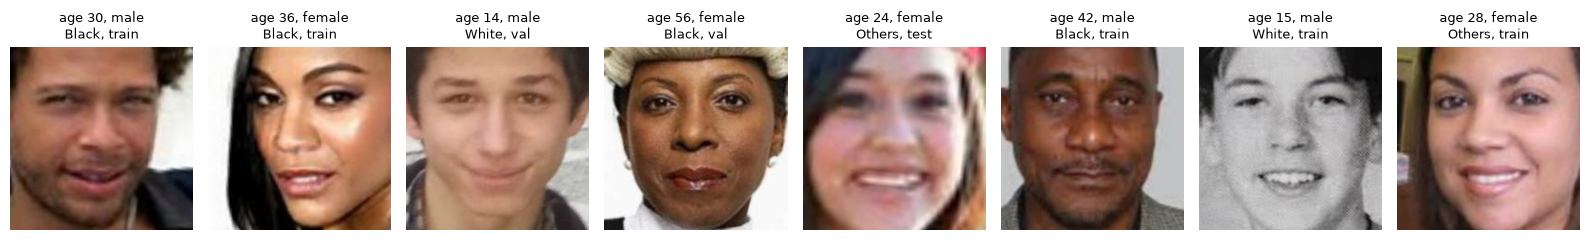

In [4]:
from concurrent.futures import ThreadPoolExecutor

from PIL import Image
import matplotlib.pyplot as plt

IMG_SIZE = 200
CACHE_NPY = CACHE_DIR / f"utkface_{IMG_SIZE}_uint8.npy"
CACHE_FILES = CACHE_DIR / f"utkface_{IMG_SIZE}_files.csv"   # row order of the cache

def load_chw(file: str) -> np.ndarray:
    """JPEG -> uint8 array (3, 200, 200)."""
    with Image.open(IMG_DIR / file) as im:
        a = np.asarray(im.convert("RGB"))                          # (H, W, C)
    assert a.shape == (IMG_SIZE, IMG_SIZE, 3), f"{file}: {a.shape}"
    return a.transpose(2, 0, 1)                                    # (C, H, W)

if not CACHE_NPY.exists():
    with track("prep_cache_200", kind="prep", gpu_ids=[0], notes="decode all JPEGs once into uint8 (N,3,200,200)") as info:
        t0 = time.time()
        out = np.lib.format.open_memmap(CACHE_NPY, mode="w+", dtype=np.uint8,
                                        shape=(len(split_df), 3, IMG_SIZE, IMG_SIZE))
        with ThreadPoolExecutor(max_workers=16) as pool:           # PIL releases the GIL while decoding
            for i, arr in enumerate(pool.map(load_chw, split_df.file, chunksize=64)):
                out[i] = arr
        out.flush(); del out
        split_df[["file"]].to_csv(CACHE_FILES, index=False)
        info["n_images"] = len(split_df); info["seconds"] = round(time.time() - t0, 1)
else:
    print(f"cache exists, not rebuilt: {CACHE_NPY.name}")

# --- load (memory-mapped) and check ---
images = np.load(CACHE_NPY, mmap_mode="r")
assert (pd.read_csv(CACHE_FILES).file.values == split_df.file.values).all(), "cache rows != split rows"
print(f"images: shape {images.shape}, dtype {images.dtype}, {images.nbytes / 1e9:.2f} GB on disk")

check = np.random.default_rng(SEED).choice(len(split_df), 8, replace=False)
for i in check:
    assert np.array_equal(images[i], load_chw(split_df.file[i])), f"row {i} differs from its JPEG"
print("8 random rows are identical to a fresh decode of their JPEG")

fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
for ax, i in zip(axes, check):
    r = split_df.iloc[i]
    ax.imshow(images[i].transpose(1, 2, 0))                       # back to (H, W, C) for plotting
    ax.set_title(f"age {r.age}, {GENDER[r.gender]}\n{RACE[r.race]}, {r.split}", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

## 5 · Standard models with a regression head

Both models are loaded with **ImageNet weights** (transfer learning) and only their **last layer** is replaced: ImageNet has 1000 classes, we predict **one number** (age).

| model | weights (decided) | ImageNet top-1 | original last layer | new last layer |
|---|---|---|---|---|
| ResNet18 | `IMAGENET1K_V1` | 69.76 % | `fc = Linear(512, 1000)` | `fc = Linear(512, 1)` |
| MobileNetV3-Large | `IMAGENET1K_V1` | 74.04 % | `classifier[3] = Linear(1280, 1000)` | `classifier[3] = Linear(1280, 1)` |

**Parameter counts by hand** (Linear: `in × out + out` for the bias):
- ResNet18: 11,689,512 − (512·1000 + 1000) + (512·1 + 1) = 11,689,512 − 513,000 + 513 = **11,177,025**
- MobileNetV3-L: 5,483,032 − (1280·1000 + 1000) + (1280·1 + 1) = 5,483,032 − 1,281,000 + 1,281 = **4,203,313**

The new layer starts with random weights; everything before it keeps the ImageNet weights.

**Input preprocessing (`to_input`)**, done on the GPU per batch from the `uint8` cache:
`x = (pixel / 255 − mean) / std` with the ImageNet `mean = (0.485, 0.456, 0.406)`, `std = (0.229, 0.224, 0.225)`, the scale the pretrained weights were trained on. No resize/crop (200 px).

The test at the end pushes 4 cached images through each model on `cuda:0` and checks that the output has shape `(4, 1)`, one predicted age per image. The predictions are meaningless for now (the head is untrained). This forward pass is logged as a `test` run.

In [5]:
import torch.nn as nn
import torchvision
from torchinfo import summary

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def to_input(batch_uint8: np.ndarray, device: str) -> torch.Tensor:
    """uint8 (B, 3, 200, 200) from the cache -> normalised float32 on the device."""
    # np.array(...) copies the batch out of the read-only memory-mapped cache (torch needs a writable array)
    x = torch.from_numpy(np.array(batch_uint8)).to(device).float().div_(255)
    return (x - IMAGENET_MEAN.to(device)) / IMAGENET_STD.to(device)

def build_model(name: str, pretrained: bool = True) -> nn.Module:
    if name == "resnet18":
        m = torchvision.models.resnet18(weights="IMAGENET1K_V1" if pretrained else None)
        print("  original head:", m.fc)
        m.fc = nn.Linear(m.fc.in_features, 1)                         # 512 -> 1
        print("  new head     :", m.fc)
    elif name == "mobilenet_v3_large":
        m = torchvision.models.mobilenet_v3_large(weights="IMAGENET1K_V1" if pretrained else None)
        print("  original head:", m.classifier[3])
        m.classifier[3] = nn.Linear(m.classifier[3].in_features, 1)   # 1280 -> 1
        print("  new head     :", m.classifier[3])
    else:
        raise ValueError(name)
    return m

def n_params(m: nn.Module) -> int:
    return sum(p.numel() for p in m.parameters())

x = to_input(images[:4], "cuda:0")
print(f"input batch: {tuple(x.shape)} {x.dtype}, mean {x.mean():.3f}, std {x.std():.3f}\n")

with track("test_heads_forward", kind="test", gpu_ids=[0], notes="forward 4 images through both models, shape check") as info:
    for name in ("resnet18", "mobilenet_v3_large"):
        print(name)
        model = build_model(name).to("cuda:0").eval()
        with torch.no_grad():
            y = model(x)
        assert y.shape == (4, 1)
        print(f"  params: {n_params(model):,} | output shape {tuple(y.shape)} | untrained predictions {y.squeeze(1).tolist()}\n")
        info[f"params_{name}"] = n_params(model)

print(summary(build_model("resnet18", pretrained=False), input_size=(1, 3, 200, 200), depth=1,
              col_names=("output_size", "num_params", "mult_adds"), verbose=0))

input batch: (4, 3, 200, 200) torch.float32, mean 0.440, std 0.989



resnet18
  original head: Linear(in_features=512, out_features=1000, bias=True)
  new head     : Linear(in_features=512, out_features=1, bias=True)
  params: 11,177,025 | output shape (4, 1) | untrained predictions [-0.06837485730648041, -0.5078461766242981, -0.6266655921936035, -0.15977643430233002]

mobilenet_v3_large
  original head: Linear(in_features=1280, out_features=1000, bias=True)
  new head     : Linear(in_features=1280, out_features=1, bias=True)


  params: 4,203,313 | output shape (4, 1) | untrained predictions [0.012532620690762997, -0.019658535718917847, -0.01390224788337946, -0.03776223957538605]

[test_heads_forward] ok | 0.2 s | 0.006 Wh (cpu 0.001, gpu 0.005, ram 0.001) | 0.003 g CO2eq
  original head: Linear(in_features=512, out_features=1000, bias=True)
  new head     : Linear(in_features=512, out_features=1, bias=True)
Layer (type:depth-idx)                   Output Shape              Param #                   Mult-Adds
ResNet                                   [1, 1]                    --                        --
├─Conv2d: 1-1                            [1, 64, 100, 100]         9,408                     94,080,000
├─BatchNorm2d: 1-2                       [1, 64, 100, 100]         128                       128
├─ReLU: 1-3                              [1, 64, 100, 100]         --                        --
├─MaxPool2d: 1-4                         [1, 64, 50, 50]           --                        --
├─Sequential: 1-5  

## 6 · Shared evaluation + the mean / median baseline

**One `evaluate()` for every model**, so all numbers in the results table are computed the same way (assignment 3.3: "same evaluation code for all models"). With $y_i$ = true age, $\hat y_i$ = prediction, $n$ images:

| metric | formula | meaning |
|---|---|---|
| MAE | $\frac{1}{n}\sum \lvert y_i-\hat y_i\rvert$ | average error in **years**; the main metric |
| RMSE | $\sqrt{\frac{1}{n}\sum (y_i-\hat y_i)^2}$ | also years, but large errors count more (squared) |
| R² | $1-\frac{\sum (y_i-\hat y_i)^2}{\sum (y_i-\bar y)^2}$ | share of the age variance explained; **0 = no better than predicting the mean**, 1 = perfect |

Plus **MAE per group** (gender, race, age band), required because UTKFace contains faces with group labels.

**Baseline (assignment 3.1):** ignore the image and always predict one number computed on **train** only:
- mean of train ages → minimises the squared error (best constant for RMSE)
- median of train ages → minimises the absolute error (best constant for MAE)

The baseline is a final "model" with nothing to tune, so it is evaluated on **val and test now**. Its test MAE is $\text{MAE}_\text{mean}$ in the acceptability rule, so it also gives us the first target:
$\text{MAE}_\text{own} \le 0.6 \times \text{MAE}_\text{mean}$.

Results go to `results/results.csv` (one row per model, the columns of the table in assignment 3.5) and the per-group errors to `results/per_group/`. The run is measured (`kind="eval"`).

In [4]:
RESULTS_CSV = REPO / "results" / "results.csv"
GROUP_DIR = REPO / "results" / "per_group"
GROUP_DIR.mkdir(parents=True, exist_ok=True)
AGE_BANDS = ["0-2", "3-12", "13-19", "20-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"]

def evaluate(y_true, y_pred, meta: pd.DataFrame | None = None) -> tuple[dict, pd.DataFrame | None]:
    """Shared metrics for every model. meta: rows of split_df in the same order (for per-group MAE)."""
    y, p = np.asarray(y_true, dtype=np.float64), np.asarray(y_pred, dtype=np.float64)
    err = p - y
    metrics = {"mae": np.abs(err).mean(),
               "rmse": np.sqrt((err ** 2).mean()),
               "r2": 1 - (err ** 2).sum() / ((y - y.mean()) ** 2).sum(),
               "n": len(y)}
    groups = None
    if meta is not None:
        m = meta.assign(abs_err=np.abs(err), gender=meta.gender.map(GENDER), race=meta.race.map(RACE))
        groups = pd.concat([m.groupby(col).abs_err.agg(mae="mean", n="size").assign(group=col)
                            for col in ("gender", "race", "age_band")])
        groups = groups.rename_axis("value").reset_index()[["group", "value", "n", "mae"]]
        order = list(GENDER.values()) + list(RACE.values()) + AGE_BANDS          # natural order, not alphabetical
        groups = groups.sort_values("value", key=lambda s: s.map(order.index), kind="stable")
    return metrics, groups

def save_result(row: dict) -> None:
    """One row per model in results/results.csv (re-running a model replaces its row)."""
    log = pd.read_csv(RESULTS_CSV) if RESULTS_CSV.exists() else pd.DataFrame()
    if len(log):
        log = log[log.model != row["model"]]
    pd.concat([log, pd.DataFrame([row])], ignore_index=True).to_csv(RESULTS_CSV, index=False)

train = split_df[split_df.split == "train"]
val   = split_df[split_df.split == "val"].reset_index(drop=True)
test  = split_df[split_df.split == "test"].reset_index(drop=True)

with track("eval_baseline_mean_median", kind="eval", gpu_ids=[0], notes="constant predictors from train stats") as info:
    rows = []
    for name, const in (("mean", train.age.mean()), ("median", train.age.median())):
        for split_name, part in (("val", val), ("test", test)):
            m, g = evaluate(part.age, np.full(len(part), const), part)
            rows.append({"baseline": name, "constant": round(const, 3), "split": split_name,
                         **{k: round(v, 3) for k, v in m.items() if k != "n"}, "n": m["n"]})
            if split_name == "test":
                g.to_csv(GROUP_DIR / f"baseline_{name}_test.csv", index=False)
                info[f"{name}_test_mae"] = round(m["mae"], 4)
    table = pd.DataFrame(rows)

print(table.to_string(index=False))

mae_mean = table.query("baseline == 'mean' and split == 'test'").mae.item()
print(f"\nMAE_mean (test)          = {mae_mean:.3f} years")
print(f"target 0.6 × MAE_mean    = {0.6 * mae_mean:.3f} years  <- own CNN must be at or below this (and ≤ 1.15 × MAE_best)")

for name in ("mean", "median"):
    r = table.query("baseline == @name and split == 'test'").iloc[0]
    save_result({"model": f"{name} baseline", "machine": MACHINE, "params": 0, "mflops_per_img": 0,
                 "test_mae": r.mae, "test_rmse": r.rmse, "test_r2": r.r2,
                 "train_kwh": 0, "train_kg_co2": 0, "project_kg_co2": None, "ms_per_img": 0})

print("\nper-group test MAE of the mean baseline:")
g = pd.read_csv(GROUP_DIR / "baseline_mean_test.csv")
with pd.option_context("display.width", 200):
    for col in ("gender", "race", "age_band"):
        t = g[g.group == col].set_index("value")[["n", "mae"]].T
        print(t.apply(lambda r: r.map("{:.0f}".format if r.name == "n" else "{:.2f}".format), axis=1).to_string(), "\n")

[eval_baseline_mean_median] ok | 0.0 s | 0.000 Wh (cpu 0.000, gpu 0.000, ram 0.000) | 0.000 g CO2eq
baseline  constant split    mae   rmse     r2    n
    mean    33.228   val 15.323 19.876 -0.000 3461
    mean    33.228  test 15.400 20.007 -0.000 3461
  median    29.000   val 14.935 20.327 -0.046 3461
  median    29.000  test 15.072 20.471 -0.047 3461

MAE_mean (test)          = 15.400 years
target 0.6 × MAE_mean    = 9.240 years  <- own CNN must be at or below this (and ≤ 1.15 × MAE_best)

per-group test MAE of the mean baseline:
value   male female
n       1802   1659
mae    15.82  14.95 

value  White  Black  Asian Indian Others
n       1474    662    505    578    242
mae    17.89  10.60  16.97  13.60  14.35 

value    0-2   3-12  13-19 20-29 30-39  40-49  50-59  60-69  70-79    80+
n        238    266    172  1064   666    328    335    192    101     99
mae    31.90  26.28  17.23  7.89  2.51  10.54  20.73  30.08  40.86  54.36 

